In [1]:
import os
from collections import Counter

DATA_DIR = r"C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder"   # change this if your dataset is somewhere else

ext_count = Counter()
folder_count = Counter()

for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        ext = os.path.splitext(f)[1].lower()
        ext_count[ext] += 1
        if ext in (".jpg", ".jpeg", ".png"):
            folder_count[root] += 1

print("File types:", dict(ext_count))
print("\nImages per folder:")
for folder, n in folder_count.items():
    print(f"  {folder}: {n}")
print("\nTotal images:", sum(folder_count.values()))

File types: {'.txt': 2, '.jpg': 110}

Images per folder:
  C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder\test\egg: 11
  C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder\train\egg: 75
  C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder\train\Unlabeled: 2
  C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder\valid\egg: 22

Total images: 110


In [2]:
# pip install imagehash pillow
import os, glob
import imagehash
from PIL import Image

DATA_DIR = r"C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder"

paths = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True))
print("Images found:", len(paths))

hashes = {p: imagehash.phash(Image.open(p)) for p in paths}

# Union-find to group images connected by a small hash distance
parent = {p: p for p in paths}
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    parent[find(a)] = find(b)

THRESH = 10   # we may tune this after looking at results
close_pairs = []
for i, a in enumerate(paths):
    for b in paths[i+1:]:
        d = hashes[a] - hashes[b]
        if d <= THRESH:
            union(a, b)
            close_pairs.append((a, b, d))

clusters = {}
for p in paths:
    clusters.setdefault(find(p), []).append(p)

sizes = sorted((len(v) for v in clusters.values()), reverse=True)
print("Similar pairs:", len(close_pairs))
print("Number of clusters:", len(clusters))
print("Cluster sizes (largest first):", sizes[:15])

print("\nSample close pairs (distance):")
for a, b, d in sorted(close_pairs, key=lambda x: x[2])[:10]:
    print(d, os.path.basename(a), "<->", os.path.basename(b))

Images found: 110
Similar pairs: 1
Number of clusters: 109
Cluster sizes (largest first): [2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Sample close pairs (distance):
4 not_damaged_78_jpg.rf.d3a6e8624d192abc58ff7df9d5781bb5.jpg <-> not_damaged_27_jpg.rf.9eabbf76d6ac2d4caccb38b11e0d28ad.jpg


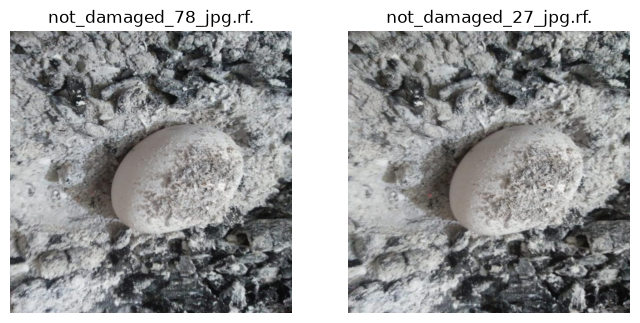

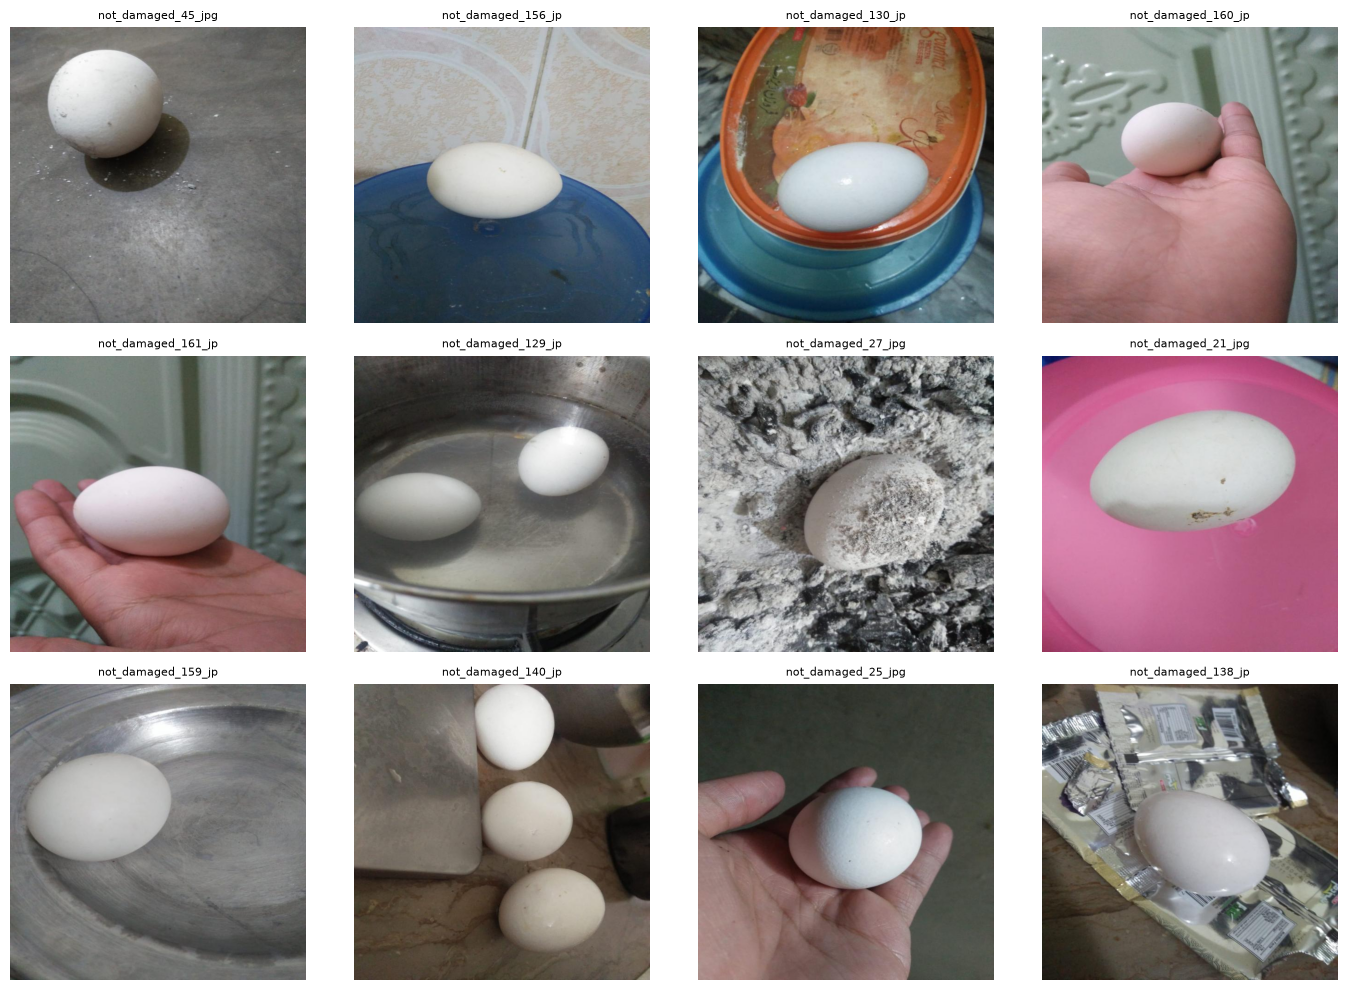

Counter({'not_damaged': 110})
Counter({(640, 640): 110})


In [3]:
import matplotlib.pyplot as plt
import random

# 1) The close pair
a, b = [p for p in close_pairs][0][:2]
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for axi, p in zip(ax, (a, b)):
    axi.imshow(Image.open(p)); axi.set_title(os.path.basename(p)[:22]); axi.axis("off")
plt.show()

# 2) Random grid of 12 images
random.seed(0)
sample = random.sample(paths, 12)
fig, ax = plt.subplots(3, 4, figsize=(14, 10))
for axi, p in zip(ax.ravel(), sample):
    axi.imshow(Image.open(p)); axi.set_title(os.path.basename(p)[:18], fontsize=8); axi.axis("off")
plt.tight_layout(); plt.show()

# 3) Count by name prefix and image size
from collections import Counter
print(Counter("damaged" if "not_damaged" not in os.path.basename(p) else "not_damaged" for p in paths))
print(Counter(Image.open(p).size for p in paths))


110 images, 138 eggs, problems: []


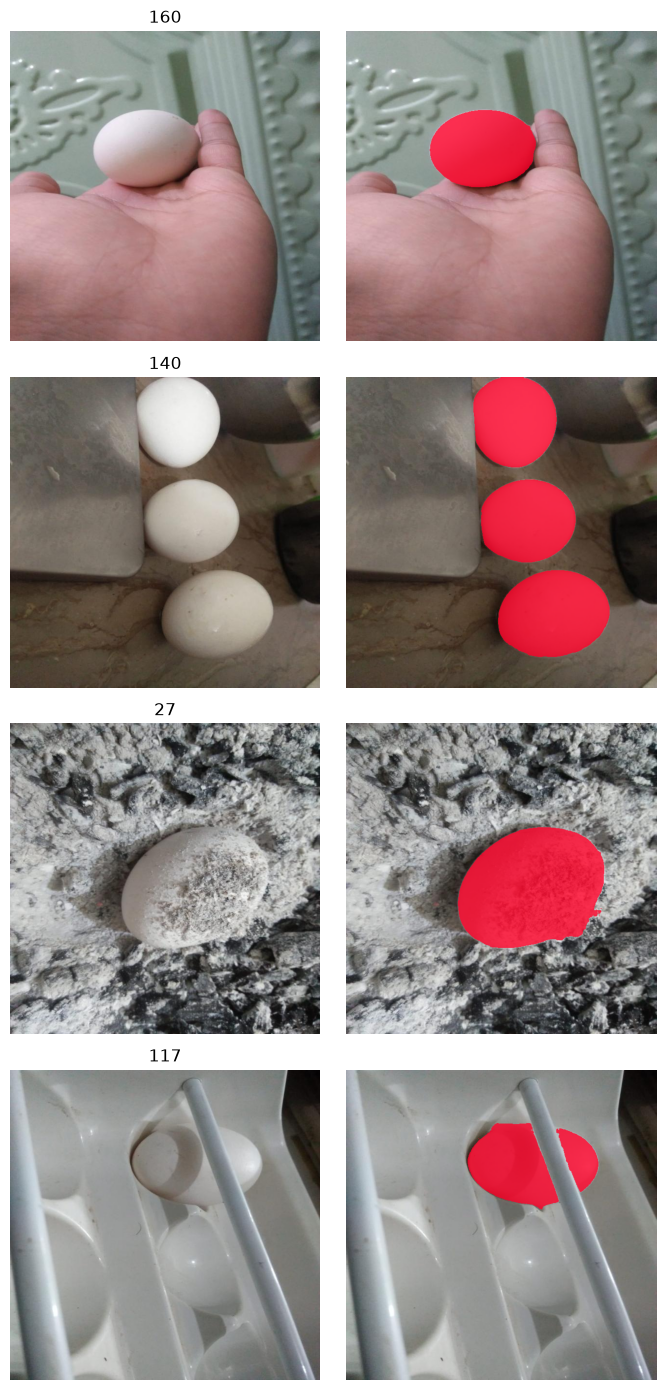

In [4]:
import glob, os, numpy as np
from PIL import Image
import matplotlib.pyplot as plt

DATA = r"C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder"
imgs = {os.path.basename(p).split("_jpg")[0]: p
        for p in glob.glob(os.path.join(DATA, "**", "*.jpg"), recursive=True)}

bad, total = [], 0
for n, p in imgs.items():
    m = np.array(Image.open(f"outputs/task1/masks/{n}.png"))
    k = len(np.unique(m)) - 1
    total += k
    if m.shape != (640, 640) or k == 0:
        bad.append(n)
print(len(imgs), "images,", total, "eggs, problems:", bad)

# example-style figure: original | solid red mask
os.makedirs("report", exist_ok=True)
show = ["not_damaged_160", "not_damaged_140", "not_damaged_27", "not_damaged_117"]
fig, ax = plt.subplots(len(show), 2, figsize=(7, 3.5 * len(show)))
for r, n in enumerate(show):
    img = np.array(Image.open(imgs[n]).convert("RGB"))
    m = np.array(Image.open(f"outputs/task1/masks/{n}.png")) > 0
    ov = img.copy()
    ov[m] = (0.2 * ov[m] + 0.8 * np.array([255, 0, 40])).astype(np.uint8)
    ax[r, 0].imshow(img); ax[r, 1].imshow(ov)
    ax[r, 0].set_title(n[-3:].strip("_")); ax[r, 0].axis("off"); ax[r, 1].axis("off")
plt.tight_layout(); plt.savefig("report/task1_examples.png", dpi=150); plt.show()

In [5]:
import glob, os, json, random
import imagehash, pandas as pd
from PIL import Image

DATA_DIR = r"C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder"
paths = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True))
name = lambda p: os.path.basename(p).split("_jpg")[0]
names = [name(p) for p in paths]
hashes = {name(p): imagehash.phash(Image.open(p)) for p in paths}

parent = {n: n for n in names}
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
for i, a in enumerate(names):
    for b in names[i+1:]:
        if hashes[a] - hashes[b] <= 10:
            parent[find(a)] = find(b)

clusters = {}
for n in names:
    clusters.setdefault(find(n), []).append(n)
clusters = list(clusters.values())

random.seed(42)
random.shuffle(clusters)
dev, ev = [], []
for c in clusters:
    (dev if len(dev) + len(c) <= 88 else ev).extend(c)

assert not set(dev) & set(ev) and len(dev) + len(ev) == 110
pair = {"not_damaged_78", "not_damaged_27"}
assert pair <= set(dev) or pair <= set(ev), "near-duplicate pair was split!"
print("dev:", len(dev), "eval:", len(ev))

os.makedirs("outputs", exist_ok=True)
json.dump({"seed": 42, "dev": sorted(dev), "eval": sorted(ev)},
          open("outputs/split.json", "w"), indent=2)

s = pd.read_csv("outputs/task1/summary_final.csv").set_index("image")
for k, v in {"dev": dev, "eval": ev}.items():
    print(k, s.loc[v, "n_eggs"].value_counts().sort_index().to_dict())

dev: 88 eval: 22
dev {1: 73, 2: 6, 3: 9}
eval {1: 20, 3: 2}


In [6]:
import random

s = pd.read_csv("outputs/task1/summary_final.csv").set_index("image")
random.seed(42)

# group clusters by the egg count of their first image
by_count = {}
for c in clusters:
    by_count.setdefault(int(s.loc[c[0], "n_eggs"]), []).append(c)

targets = {1: 19, 2: 2, 3: 2}      # eval images per egg-count group (sums to 23, trimmed below)
dev, ev = [], []
for k, cl in by_count.items():
    random.shuffle(cl)
    got = 0
    for c in cl:
        if got < targets[k]:
            ev.extend(c); got += len(c)
        else:
            dev.extend(c)

# trim/adjust to exactly 22 eval images by moving single-egg clusters of size 1
while len(ev) > 22:
    for n in ev:
        if int(s.loc[n, "n_eggs"]) == 1 and n not in pair:
            ev.remove(n); dev.append(n); break
while len(ev) < 22:
    for n in dev:
        if int(s.loc[n, "n_eggs"]) == 1 and n not in pair:
            dev.remove(n); ev.append(n); break

assert not set(dev) & set(ev) and len(dev) == 88 and len(ev) == 22
assert pair <= set(dev) or pair <= set(ev), "near-duplicate pair was split!"
json.dump({"seed": 42, "method": "cluster-level, stratified by egg count",
           "dev": sorted(dev), "eval": sorted(ev)},
          open("outputs/split.json", "w"), indent=2)
for k, v in {"dev": dev, "eval": ev}.items():
    print(k, len(v), s.loc[v, "n_eggs"].value_counts().sort_index().to_dict())

dev 88 {1: 75, 2: 4, 3: 9}
eval 22 {1: 18, 2: 2, 3: 2}


In [7]:
import numpy as np, json
from PIL import Image
from scipy.optimize import linear_sum_assignment

SPLIT = json.load(open("outputs/split.json"))
DEV, EVAL = SPLIT["dev"], SPLIT["eval"]

def load_gt(name):
    """Task 1 instance map -> list of boolean masks (one per egg)."""
    inst = np.array(Image.open(f"outputs/task1/masks/{name}.png"))
    return [inst == i for i in np.unique(inst) if i != 0]

def iou(a, b):
    u = (a | b).sum()
    return (a & b).sum() / u if u else 1.0

def dice(a, b):
    s = a.sum() + b.sum()
    return 2 * (a & b).sum() / s if s else 1.0

def score_image(pred_masks, gt_masks, match_thr=0.5):
    """
    pred_masks, gt_masks: lists of boolean (H, W) arrays.
    Returns pixel-level (all eggs merged) and instance-level metrics.
    """
    H, W = gt_masks[0].shape
    P = np.zeros((H, W), bool); G = np.zeros((H, W), bool)
    for m in pred_masks: P |= m
    for m in gt_masks:   G |= m

    tp = (P & G).sum(); fp = (P & ~G).sum(); fn = (~P & G).sum()
    out = {
        "iou": iou(P, G), "dice": dice(P, G),
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "recall": tp / (tp + fn) if tp + fn else 0.0,
        "n_gt": len(gt_masks), "n_pred": len(pred_masks),
    }

    # instance level: Hungarian matching on IoU
    matched_ious = []
    if pred_masks and gt_masks:
        M = np.array([[iou(p, g) for g in gt_masks] for p in pred_masks])
        r, c = linear_sum_assignment(-M)
        matched_ious = [M[i, j] for i, j in zip(r, c) if M[i, j] >= match_thr]
    out["tp_inst"] = len(matched_ious)
    out["fp_inst"] = len(pred_masks) - len(matched_ious)
    out["fn_inst"] = len(gt_masks) - len(matched_ious)
    out["mean_matched_iou"] = float(np.mean(matched_ious)) if matched_ious else 0.0
    return out

def evaluate(segment_fn, names, load_img):
    """segment_fn(rgb_array) -> list of boolean masks. Returns a DataFrame."""
    import pandas as pd
    rows = []
    for n in names:
        pred = segment_fn(load_img(n))
        r = score_image(pred, load_gt(n)); r["image"] = n
        rows.append(r)
    return pd.DataFrame(rows)

In [8]:
g = load_gt("not_damaged_140")
print("perfect:", score_image(g, g)["iou"])                       # expect 1.0
print("empty  :", score_image([], g)["iou"])                      # expect 0.0
shifted = [np.roll(m, 20, axis=1) for m in g]
r = score_image(shifted, g); print("shifted:", round(r["iou"], 3), r["tp_inst"], "of", r["n_gt"])
print("merged :", score_image([np.logical_or.reduce(g)], g)["tp_inst"], "of", len(g), "(expect low)")

perfect: 1.0
empty  : 0.0
shifted: 0.775 3 of 3
merged : 0 of 3 (expect low)


In [9]:
import glob, os, json, cv2
import pandas as pd

DATA_DIR = r"C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder"
IMG_PATHS = {os.path.basename(p).split("_jpg")[0]: p
             for p in glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True)}

def load_img(name):
    return np.array(Image.open(IMG_PATHS[name]).convert("RGB"))

def summarize(df):
    return {
        "mean_iou": round(df.iou.mean(), 4), "median_iou": round(df.iou.median(), 4),
        "mean_dice": round(df.dice.mean(), 4),
        "precision": round(df.precision.mean(), 4), "recall": round(df.recall.mean(), 4),
        "inst_precision": round(df.tp_inst.sum() / max(df.n_pred.sum(), 1), 4),
        "inst_recall": round(df.tp_inst.sum() / df.n_gt.sum(), 4),
        "count_mae": round((df.n_pred - df.n_gt).abs().mean(), 4),
    }

def log_trial(trial_id, change, why, params, df, split="dev"):
    if split == "dev":   # guard against touching the eval set during development
        assert set(df.image) <= set(DEV), "eval images found in a dev trial!"
    os.makedirs("outputs/task2", exist_ok=True)
    row = {"trial": trial_id, "split": split, "change": change, "why": why,
           "params": json.dumps(params), **summarize(df)}
    f = "outputs/task2/trials.csv"
    pd.concat([pd.read_csv(f), pd.DataFrame([row])]) if os.path.exists(f) else pd.DataFrame([row])
    out = pd.concat([pd.read_csv(f), pd.DataFrame([row])]) if os.path.exists(f) else pd.DataFrame([row])
    out.to_csv(f, index=False)
    df.to_csv(f"outputs/task2/per_image_{trial_id}.csv", index=False)
    return row

In [10]:
def seg_t1(rgb, min_area=2000):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    _, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(bw)
    return [lab == i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= min_area]

df1 = evaluate(seg_t1, DEV, load_img)
print(log_trial("T1", "Grayscale + Otsu + connected components",
                "Simplest possible baseline", {"min_area": 2000}, df1))

{'trial': 'T1', 'split': 'dev', 'change': 'Grayscale + Otsu + connected components', 'why': 'Simplest possible baseline', 'params': '{"min_area": 2000}', 'mean_iou': np.float64(0.3379), 'median_iou': np.float64(0.2383), 'mean_dice': np.float64(0.453), 'precision': np.float64(0.3722), 'recall': np.float64(0.8677), 'inst_precision': np.float64(0.1963), 'inst_recall': np.float64(0.3909), 'count_mae': np.float64(1.3977)}


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [2.0..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [16.5..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [7.0..244.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [9.0..253.5].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [3.0..254.5].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [2.0..254.5].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [18.0..255.0].
Clipping input data to the valid range for imshow with RGB d

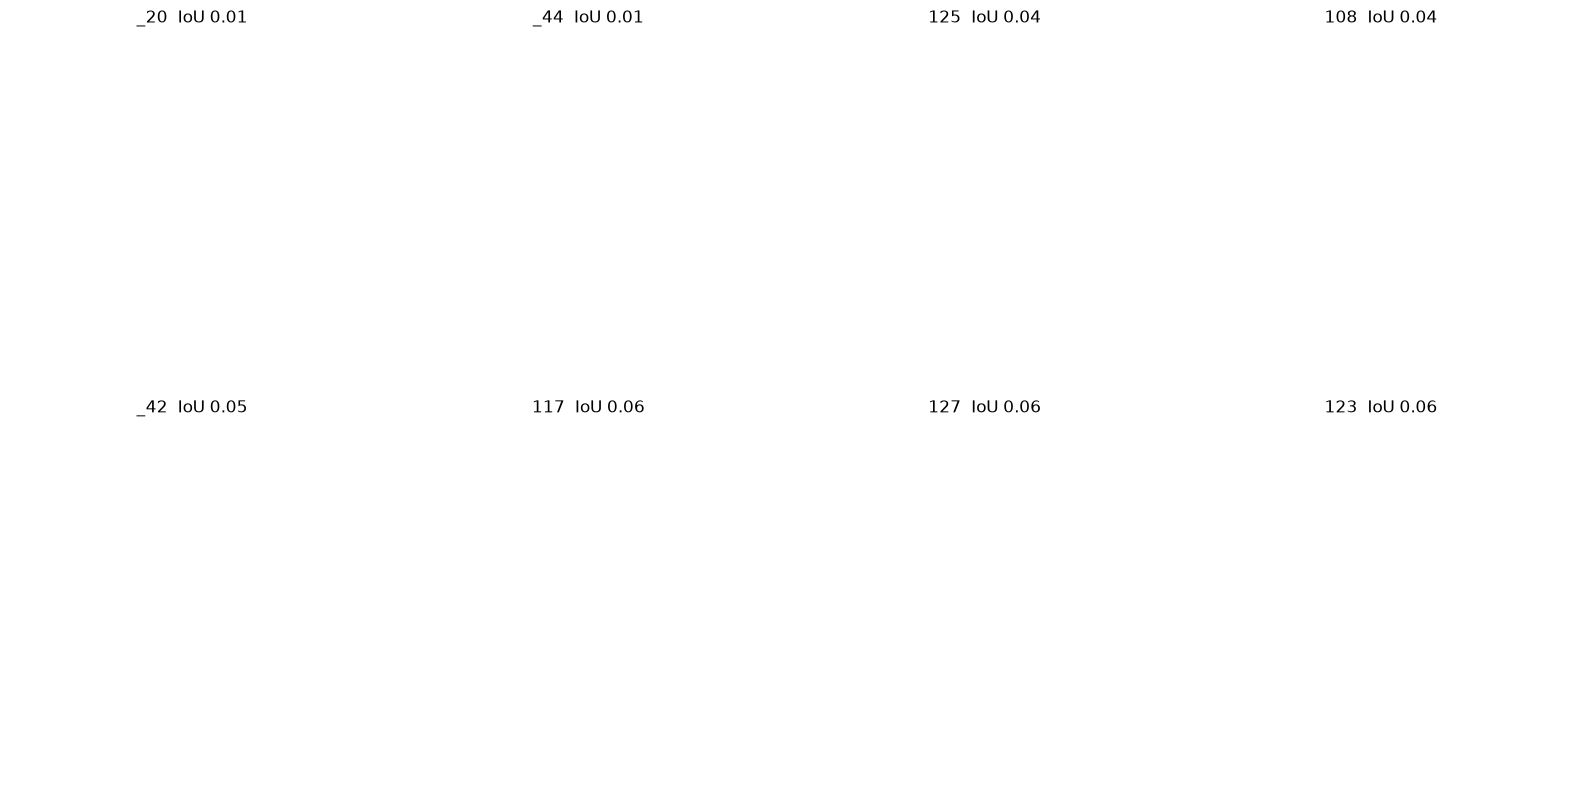

In [11]:
import matplotlib.pyplot as plt

def show_worst(df, seg_fn, k=8):
    worst = df.sort_values("iou").head(k)["image"].tolist()
    fig, ax = plt.subplots(2, k // 2 * 2 // 2 if False else 4, figsize=(16, 8))
    for a, n in zip(ax.ravel(), worst):
        img = load_img(n); ov = img.copy()
        P = np.logical_or.reduce(seg_fn(img)) if seg_fn(img) else np.zeros(img.shape[:2], bool)
        G = np.logical_or.reduce(load_gt(n))
        ov[G & ~P] = [0, 0, 255]      # blue = missed egg
        ov[P & ~G] = [255, 0, 0]      # red  = false foreground
        ov[P & G]  = [0, 255, 0]      # green = correct
        a.imshow(0.5 * img + 0.5 * ov); a.set_title(f"{n[-3:]}  IoU {df.set_index('image').loc[n,'iou']:.2f}"); a.axis("off")
    plt.tight_layout(); plt.show()

show_worst(df1, seg_t1)